# 08 Support Vector Machines (linear and Gaussian)
Two SVMs side by side: a **linear** kernel (straight decision boundary) and a **Gaussian / RBF** kernel (curved boundary).
Same feature table, season split and evaluation as notebooks 03-06. The test seasons stay reserved for the final comparison, like notebooks 05 and 06.

### Step 1: imports

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.exceptions import ConvergenceWarning

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8a85"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "legend.frameon": False})

### Step 2: load the shared feature table and split by season
`model_table.csv` comes from notebook 02: cleaned games, 76 pre-game features, no IDs. Train 2003-2016, validation 2017-2018, test 2019-2022 (reserved).

In [2]:
data = pd.read_csv("../src/dataset/model_table.csv", parse_dates=["GAME_DATE"])

feature_cols = [c for c in data.columns if c not in ("GAME_DATE", "SEASON", "SPLIT", "HOME_TEAM_WINS")]
X = data[feature_cols]
y = data["HOME_TEAM_WINS"]
is_train, is_val, is_test = (data["SPLIT"] == s for s in ("train", "validation", "test"))

print(len(feature_cols), "features")
data.groupby("SPLIT", sort=False).agg(games=("SPLIT", "size"), first_season=("SEASON", "min"), last_season=("SEASON", "max"))

76 features


,games,first_season,last_season
SPLIT,,,
train,18110,2003,2016
validation,2624,2017,2018
test,4114,2019,2022


### Step 3: evaluation (same cell in every model notebook)

In [3]:
def evaluate(name, y_true, y_prob, threshold=0.5):
    y_prob = np.clip(np.asarray(y_prob, dtype=float), 1e-6, 1 - 1e-6)
    y_pred = (y_prob >= threshold).astype(int)
    return {"model": name,
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, y_prob),
            "log_loss": log_loss(y_true, y_prob, labels=[0, 1])}

def plot_cm(ax, y_true, y_prob, title):
    cm = confusion_matrix(y_true, (np.asarray(y_prob) >= 0.5).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["away win", "home win"], yticklabels=["away win", "home win"])
    ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title(title)

### Step 4: the SVM pipeline
SVMs need scaled features. The pipeline fills missing values with the **training** median and scales with **training** statistics, so nothing leaks from validation or test.
`probability=True` makes the SVM output a win probability (Platt scaling, fitted with a small internal 5-fold split of the training data). It is only needed for the final models, because tuning uses the SVM score directly.

In [4]:
def make_svm(kernel, C, gamma="scale", probability=False):
    svm = SVC(kernel=kernel, C=C, gamma=gamma, probability=probability, random_state=42,
              max_iter=2_000_000)   # cap so a slow linear fit cannot run forever
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()),
                     ("svm", svm)])

def fit_quiet(model, X_fit, y_fit):
    # returns True if the solver hit the iteration cap
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_fit, y_fit)
    return any(issubclass(x.category, ConvergenceWarning) for x in w)

### Step 5: default models (the coding-assignment-3 setup)
Linear with C = 1, and RBF with C = 1 and `gamma="scale"` (= 1 / number of features after scaling, about 0.013). These are the "before tuning" models.

In [5]:
defaults = {}
for name, kernel in (("linear", "linear"), ("rbf", "rbf")):
    t0 = time.time()
    model = make_svm(kernel, C=1, probability=True)
    capped = fit_quiet(model, X[is_train], y[is_train])
    defaults[name] = model
    print(f"default {name} SVM: trained in {time.time() - t0:.1f}s" + ("  (hit iteration cap)" if capped else ""))

default linear SVM: trained in 173.1s  (hit iteration cap)


default rbf SVM: trained in 55.9s


### Step 6: tune with forward-chaining folds
Same 5 folds as notebooks 04 and 05: train on all earlier training seasons, validate on 2012, 2013, 2014, 2015 and 2016.

- **Linear:** C in 0.001, 0.01, 0.1, 1.
- **RBF:** C in 0.1, 1, 10 and gamma in "scale" (about 0.013) and 0.001.

C is the penalty for misclassified points: a large C fits the training data more tightly. Gamma controls how far one game's influence reaches in the RBF kernel: a large gamma gives a wigglier boundary.
Each setting is scored by **mean fold ROC-AUC**, computed from the SVM score (`decision_function`), so no probabilities are needed. Train and fold accuracy are recorded too, for the fit check in Step 7.

In [6]:
fold_seasons = [2012, 2013, 2014, 2015, 2016]
season = data["SEASON"]

grid = ([("linear", C, "scale") for C in [0.001, 0.01, 0.1, 1]] +
        [("rbf", C, g) for C in [0.1, 1, 10] for g in ["scale", 0.001]])

t0 = time.time()
rows = []
for kernel, C, gamma in grid:
    fold = {"auc": [], "val_acc": [], "train_acc": []}
    capped = False
    for s in fold_seasons:
        fit_mask = is_train & (season < s)
        score_mask = is_train & (season == s)
        model = make_svm(kernel, C, gamma)
        capped |= fit_quiet(model, X[fit_mask], y[fit_mask])
        score = model.decision_function(X[score_mask])
        fold["auc"].append(roc_auc_score(y[score_mask], score))
        fold["val_acc"].append(accuracy_score(y[score_mask], (score > 0).astype(int)))
        fold["train_acc"].append(accuracy_score(y[fit_mask], model.predict(X[fit_mask])))
    rows.append({"kernel": kernel, "C": C, "gamma": gamma,
                 "fold_auc_mean": np.mean(fold["auc"]), "fold_auc_std": np.std(fold["auc"]),
                 "fold_val_acc": np.mean(fold["val_acc"]), "fold_train_acc": np.mean(fold["train_acc"]),
                 "hit_iter_cap": capped})
    print(f"{kernel:6s} C={C:<6} gamma={str(gamma):5s} fold AUC {np.mean(fold['auc']):.4f}  ({time.time() - t0:.0f}s so far)")

tuning = pd.DataFrame(rows)
tuning.round(4)

linear C=0.001  gamma=scale fold AUC 0.7198  (36s so far)


linear C=0.01   gamma=scale fold AUC 0.7170  (70s so far)


linear C=0.1    gamma=scale fold AUC 0.7102  (117s so far)


linear C=1      gamma=scale fold AUC 0.7090  (244s so far)


rbf    C=0.1    gamma=scale fold AUC 0.7002  (320s so far)


rbf    C=0.1    gamma=0.001 fold AUC 0.7162  (395s so far)


rbf    C=1      gamma=scale fold AUC 0.6897  (473s so far)


rbf    C=1      gamma=0.001 fold AUC 0.7139  (546s so far)


rbf    C=10     gamma=scale fold AUC 0.6461  (694s so far)


rbf    C=10     gamma=0.001 fold AUC 0.7055  (769s so far)


,kernel,C,gamma,fold_auc_mean,fold_auc_std,fold_val_acc,fold_train_acc,hit_iter_cap
0,linear,0.001,scale,0.7198,0.0155,0.6721,0.6757,False
1,linear,0.010,scale,0.7170,0.0151,0.6696,0.6752,False
2,linear,0.100,scale,0.7102,0.0152,0.6706,0.6758,False
3,linear,1.000,scale,0.7090,0.0151,0.6704,0.6757,True
4,rbf,0.100,scale,0.7002,0.0174,0.6617,0.6776,False
5,rbf,0.100,0.001,0.7162,0.0170,0.6575,0.6686,False
6,rbf,1.000,scale,0.6897,0.0186,0.6616,0.7192,False
7,rbf,1.000,0.001,0.7139,0.0141,0.6636,0.6737,False
8,rbf,10.000,scale,0.6461,0.0169,0.6285,0.8874,False
9,rbf,10.000,0.001,0.7055,0.0141,0.6646,0.6804,False


In [7]:
# best setting per kernel: highest mean fold ROC-AUC (ties -> smaller C)
best = {}
for kernel in ("linear", "rbf"):
    t = tuning[tuning["kernel"] == kernel].sort_values(["fold_auc_mean", "C"], ascending=[False, True])
    best[kernel] = t.iloc[0]
    print(f"best {kernel}: C = {best[kernel]['C']}, gamma = {best[kernel]['gamma']}, "
          f"mean fold AUC = {best[kernel]['fold_auc_mean']:.4f}")

best linear: C = 0.001, gamma = scale, mean fold AUC = 0.7198
best rbf: C = 0.1, gamma = 0.001, mean fold AUC = 0.7162


### Step 7: fit check: train vs fold accuracy as C grows
If the train line climbs while the fold (validation) line stays flat or falls, the model is starting to overfit. Two low lines close together mean underfitting.

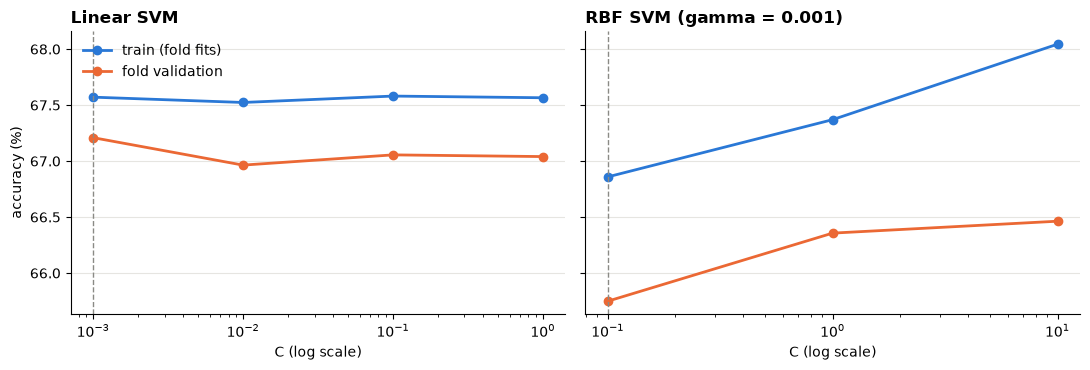

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
panels = [("linear", tuning[tuning["kernel"] == "linear"], "Linear SVM"),
          ("rbf", tuning[(tuning["kernel"] == "rbf") & (tuning["gamma"] == best["rbf"]["gamma"])],
           f"RBF SVM (gamma = {best['rbf']['gamma']})")]
for ax, (kernel, t, title) in zip(axes, panels):
    t = t.sort_values("C")
    ax.plot(t["C"], t["fold_train_acc"] * 100, marker="o", lw=2, color=BLUE, label="train (fold fits)")
    ax.plot(t["C"], t["fold_val_acc"] * 100, marker="o", lw=2, color=ORANGE, label="fold validation")
    ax.axvline(best[kernel]["C"], color=GRAY, ls="--", lw=1)
    ax.set_xscale("log"); ax.set_xlabel("C (log scale)"); ax.set_title(title)
    ax.grid(axis="y", color="#e6e5e1")
axes[0].set_ylabel("accuracy (%)"); axes[0].legend(loc="upper left")
plt.tight_layout(); plt.show()

### Step 8: final models and results (train and validation)
The best setting for each kernel is refitted on all training seasons with probabilities turned on. Majority and logistic regression rows are included for comparison (logistic regression numbers copied from notebook 05).

In [9]:
tuned = {}
for kernel in ("linear", "rbf"):
    t0 = time.time()
    model = make_svm(kernel, C=float(best[kernel]["C"]), gamma=best[kernel]["gamma"], probability=True)
    fit_quiet(model, X[is_train], y[is_train])
    tuned[kernel] = model
    print(f"tuned {kernel} SVM trained in {time.time() - t0:.1f}s")

rows, probs = [], {}
for part, mask in (("train", is_train), ("validation", is_val)):
    rows.append(evaluate(f"majority ({part})", y[mask], np.full(int(mask.sum()), y[is_train].mean())))
    for kernel in ("linear", "rbf"):
        for label, model in (("default", defaults[kernel]), ("tuned", tuned[kernel])):
            p = model.predict_proba(X[mask])[:, 1]
            probs[(kernel, label, part)] = p
            rows.append(evaluate(f"SVM {kernel} {label} ({part})", y[mask], p))
results = pd.DataFrame(rows).set_index("model")

# logistic regression (tuned) from notebook 05, for comparison
lr = pd.DataFrame({"accuracy": [0.6743, 0.6658], "roc_auc": [0.7198, 0.7029], "log_loss": [0.5983, 0.6142]},
                  index=["logistic regression, nb 05 (train)", "logistic regression, nb 05 (validation)"])
pd.concat([results, lr]).round(4)

tuned linear SVM trained in 33.5s


tuned rbf SVM trained in 51.3s


,accuracy,precision,recall,f1,roc_auc,log_loss
majority (train),0.5996,0.5996,1.0000,0.7497,0.5000,0.6732
SVM linear default (train),0.6742,0.6873,0.8378,0.7551,0.7127,0.6062
SVM linear tuned (train),0.6748,0.6919,0.8248,0.7526,0.7188,0.5995
SVM rbf default (train),0.7121,0.7095,0.8804,0.7857,0.7982,0.5661
SVM rbf tuned (train),0.6721,0.6846,0.8401,0.7544,0.7151,0.6046
majority (validation),0.5888,0.5888,1.0000,0.7412,0.5000,0.6775
SVM linear default (validation),0.6623,0.6701,0.8401,0.7455,0.6976,0.6187
SVM linear tuned (validation),0.6639,0.6749,0.8278,0.7436,0.7032,0.6136
SVM rbf default (validation),0.6444,0.6501,0.8576,0.7396,0.6735,0.6337
SVM rbf tuned (validation),0.6555,0.6665,0.8304,0.7395,0.7014,0.6169


### Step 9: confusion matrices (validation)

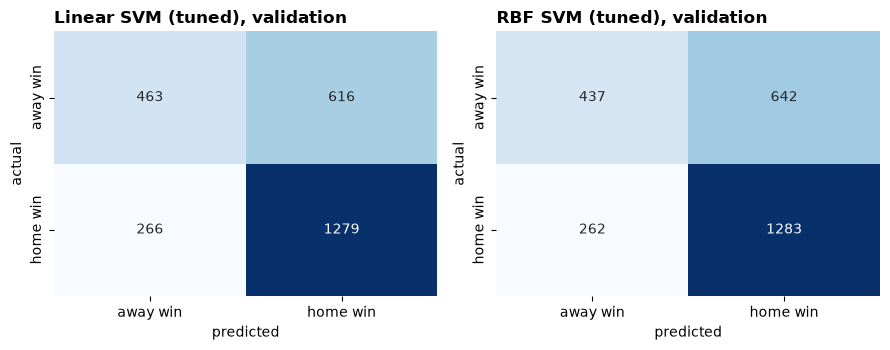

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
plot_cm(axes[0], y[is_val], probs[("linear", "tuned", "validation")], "Linear SVM (tuned), validation")
plot_cm(axes[1], y[is_val], probs[("rbf", "tuned", "validation")], "RBF SVM (tuned), validation")
plt.tight_layout(); plt.show()

### Step 10: observation
Observation: **Linear SVM.** Forward-chaining tuning picked C = 0.001, the strongest regularization in the grid (mean fold ROC-AUC 0.7198), but every C from 0.001 to 1 lands within 0.3 points of fold accuracy, so the setting barely matters. The tuned linear SVM reaches 67.48% on train and 66.39% on validation (ROC-AUC 0.7032, log loss 0.6136), essentially the same as logistic regression (66.58%, 0.7029, 0.6142). That is expected: both draw a straight boundary through the same 76 features. Train and validation differ by about 1 point, so it is a good fit, if anything slightly underfitting. The default (C = 1) gives almost the same result but is slow (173s) and hit the iteration cap.

**RBF SVM.** The coding-assignment default (C = 1, gamma = "scale") **overfits**: 71.21% on train but 64.44% on validation, worse than the linear SVM. Larger C makes it worse: with C = 10 and gamma = "scale" the fold fits reach 88.74% on train but only 62.85% on the fold seasons. Tuning picked a much smoother boundary (C = 0.1, gamma = 0.001; mean fold ROC-AUC 0.7162), which removes most of the overfitting (67.21% train vs 65.55% validation, ROC-AUC 0.7014, log loss 0.6169), but it still does not beat the linear SVM. A curved boundary does not help here.

Note on tuning: settings were chosen by fold ROC-AUC (how well the model ranks games), the same idea as log loss in notebooks 04 and 05. For the RBF kernel with gamma = 0.001, a larger C gives slightly higher fold accuracy (66.5% at C = 10) but lower ROC-AUC, so the metrics disagree a little. Both best settings sit at the edge of the grid (smallest C, smallest gamma), so a check with even smaller values is a cheap next step, though the flat linear results suggest it will not change much.

**Conclusion:** the linear SVM (66.39%) is better than the RBF SVM (65.55%) on validation, and both match logistic regression. Like Elo, logistic regression and the random forest, the SVMs stop at about 66%, which again points to the features, not the model, as the limit. The confusion matrices show the same main mistake as the other models: predicting a home win when the away team wins (616 and 642 games).

Next steps: extend the grid downward (C = 0.0001; gamma = 0.0001) as a check, keep the test seasons for the final comparison, and use the RBF overfitting (default and C = 10) as an example in the final presentation.

### Step 11: feature selection
Feature selection is done for all models in **`09_feature_selection.ipynb`**. Its final check refits both SVMs with the settings tuned here, on the 10 features selected by mutual information (training seasons only), and compares them with all 76 features:

| SVM (tuned settings) | Validation accuracy, all 76 | Validation accuracy, selected 10 | Training time |
|---|---|---|---|
| Linear (C = 0.001) | 66.39% | 65.59% | 34s -> 18s |
| RBF (C = 0.1, gamma = 0.001) | 65.55% | 65.47% | 52s -> 31s |

Observation: feature selection **halves the training time** but **does not improve accuracy** for either SVM (log loss is almost unchanged). We keep all 76 features for the final SVM results. The 10-feature set is a reasonable faster option if the RBF SVM needs to be tuned on a wider grid.